# 01-5. 도로·지형 자료와 목표안개 관측소

01의 11~12장입니다. 고속도로 중심선, 교량·터널 위치(제공 CSV), 국토부 경계 자료(zip), 목표안개 관측소 자료를 점검합니다.

제공 자료 4·5·6·8번과 01-2의 목표안개 자료를 읽습니다. 고속도로 주변 교량 polygon과 고속도로 터널은 `data/interim/bridge_poly.gpkg`, `hw_tunnels.gpkg`에 저장해서 01-7의 13-7·13-8에서 씁니다.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parents[1]  # notebooks/<단계 폴더>/ 에서 실행
sys.path.insert(0, str(ROOT))

from src import config

In [2]:
import warnings
import zipfile

import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd
import pyogrio
from cycler import cycler
from matplotlib import font_manager

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

# 한글 글꼴 (설치된 것 중 먼저 찾은 것)
for font in ["NanumGothic", "Malgun Gothic", "AppleGothic"]:
    if any(f.name == font for f in font_manager.fontManager.ttflist):
        plt.rcParams["font.family"] = font
        break
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
plt.rcParams.update({
    "axes.unicode_minus": False,
    "axes.prop_cycle": cycler(color=PALETTE),
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "axes.edgecolor": "#c3c2b7", "axes.spines.top": False, "axes.spines.right": False,
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "figure.dpi": 100, "lines.linewidth": 1.5,
})
ROUTE_COLORS = {"서해안": PALETTE[0], "호남선": PALETTE[1], "통영-대전중부선": PALETTE[2]}
INK, MUTED = "#0b0b0b", "#898781"
HOLDOUT = list(config.HOLDOUT_STATIONS)
CRS = 5179

In [3]:
fog = pd.read_parquet(config.INTERIM_DIR / "fog.parquet")  # 01-2(3-6)에서 저장한 목표안개 관측 자료
centerline = gpd.read_file(config.RAW_DIR / config.RAW_FILES["centerline"])
print("목표안개:", fog.shape, "/ 중심선 선형:", len(centerline))

목표안개: (69118, 11) / 중심선 선형: 1471


## 11. 도로·지형 자료

### 11-1. 고속도로 중심선

In [4]:
centerline["길이_m"] = centerline.length
cl_tbl = centerline.groupby("NAME").agg(
    선형수=("UFID", "size"), 총연장_km=("길이_m", lambda s: s.sum() / 1000),
    양방통행_km=("길이_m", lambda s: s[centerline.loc[s.index, "ONSD"] == "ITH002"].sum() / 1000),
    일방통행_km=("길이_m", lambda s: s[centerline.loc[s.index, "ONSD"] == "ITH001"].sum() / 1000),
    차로수_최빈=("RDLN", lambda s: s.mode()[0]), 도로폭_중앙값=("RVWD", "median"))
cl_tbl.round(1)

,선형수,총연장_km,양방통행_km,일방통행_km,차로수_최빈,도로폭_중앙값
NAME,,,,,,
서해안고속국도,655,113.9,96.3,17.6,4,23.0
통영-대전고속국도,258,61.8,37.7,24.1,4,18.2
호남고속국도,558,100.2,86.8,13.4,4,23.5


In [5]:
centerline.groupby(["NAME", "RDLN"])["길이_m"].agg(["count", "sum"]).round(0).unstack(0)

count                       sum                   
NAME 서해안고속국도 통영-대전고속국도 호남고속국도  서해안고속국도 통영-대전고속국도   호남고속국도
RDLN                                                     
1      113.0      44.0  133.0   8997.0    3459.0   9900.0
2       79.0      83.0   70.0   9021.0   23778.0   6849.0
3        3.0       6.0    NaN     90.0    1640.0      NaN
4      445.0     118.0  262.0  94917.0   31641.0  61893.0
5        NaN       7.0    5.0      NaN    1278.0    324.0
6       15.0       NaN   56.0    915.0       NaN   6976.0
8        NaN       NaN   32.0      NaN       NaN  14210.0

중심선 설명서(연속수치지형도 도로중심선)로 속성을 확인했습니다. `NAME`의 서해안고속국도, 호남고속국도, 통영-대전고속국도가 RWIS 노선명(서해안, 호남선, 통영-대전중부선)과 대응합니다. `ONSD`는 ITH001이 일방통행, ITH002가 양방통행이고 `RDLN`은 차로수, `DVYN`은 분리대 유무, `RVWD`는 도로폭입니다.

일방통행이거나 1~2차로인 선형에는 IC·JC 연결로와 상·하행이 분리된 구간이 섞여 있습니다. 구간 분할(02-2)에서는 본선만 골라 씁니다.

### 11-2. 교량·터널 위치 (제공 CSV)

In [6]:
bridges = pd.read_csv(config.RAW_DIR / config.RAW_FILES["bridge"], encoding=config.CSV_ENCODING)
tunnels = pd.read_csv(config.RAW_DIR / config.RAW_FILES["tunnel"], encoding=config.CSV_ENCODING)
print("교량 컬럼:", list(bridges.columns))
print("터널 컬럼:", list(tunnels.columns))
print(f"교량 {len(bridges)}행 → 중복 제거 {len(bridges.drop_duplicates())}행, "
      f"시작점≠종료점 {(bridges['교량시작점위도'] != bridges['교량종료점위도']).sum()}행")
print(f"터널 {len(tunnels)}행 → 중복 제거 {len(tunnels.drop_duplicates())}행")
pd.concat([bridges.drop_duplicates()["도로노선명"].value_counts().rename("교량"),
           tunnels.drop_duplicates()["도로노선명"].value_counts().rename("터널")], axis=1).fillna(0).astype(int)

교량 컬럼: ['도로노선명', '시도명', '교량시작점위도', '교량시작점경도', '교량종료점위도', '교량종료점경도']
터널 컬럼: ['도로노선명', '시도명', '터널시작점경도', '터널시작점위도', '터널종료점경도', '터널종료점위도']
교량 453행 → 중복 제거 151행, 시작점≠종료점 2행
터널 14행 → 중복 제거 7행


,교량,터널
도로노선명,,
서해안고속국도,75,1
호남고속국도,43,1
중부고속국도,33,5


교량 CSV는 위도·경도 순이고 터널 CSV는 경도·위도 순입니다. 시작점과 종료점이 거의 같아 길이 정보가 없고 행이 2개씩 중복되어 있습니다(상·하행으로 추정). 중복을 빼면 교량 151개, 터널 7개입니다. 통영-대전 노선은 CSV에서 `중부고속국도`로 적혀 있습니다.

### 11-3. 국토부 경계 데이터 (zip)

In [7]:
zip_path = config.RAW_DIR / config.RAW_FILES["boundary"]
with zipfile.ZipFile(zip_path) as z:
    shp_files = [n for n in z.namelist() if n.endswith(".shp")]
    other_files = [n for n in z.namelist() if n.endswith((".xlsx", ".pdf"))]
layers = []
for name in shp_files:
    info = pyogrio.read_info(f"/vsizip/{zip_path}/{name}")
    layers.append({"레이어": name.split("/")[-2], "좌표계": info["crs"], "객체수": info["features"],
                   "형태": info["geometry_type"], "인코딩": info["encoding"], "속성": ", ".join(info["fields"][:8])})
print("기타 파일:", [n.split("/")[-1] for n in other_files])
pd.DataFrame(layers)

기타 파일: ['국가기본도_하천경계_테이블정의서.xlsx', '연속수치지형도_데이터_설명서.pdf']


,레이어,좌표계,객체수,형태,인코딩,속성
0,C_UQ151(도로)_전북도_국토부_디지털트윈국토,EPSG:5174,260432,Polygon,ISO-8859-1,"PRESENT_SN, LCLAS_CL, MLSFC_CL, SCLAS_CL, ATRB..."
1,LSMD_CONT_UI201_전북도(고속국도 접도구역)_국토부_디지털트윈국토,EPSG:5186,798,Polygon,ISO-8859-1,"NTFDATE, ALIAS, REMARK, MNUM, COL_ADM_SE, SGG_OID"
2,N3A_A0070000(교량)_국토부_디지털트윈국토,EPSG:5179,168597,Polygon,UTF-8,"UFID, NAME, KIND, LENG, WIDT, EYMD, QUAL, RVNM"
3,N3A_A0110020(터널)_국토부_디지털트윈국토,EPSG:5179,3566,Polygon,UTF-8,"UFID, NAME, LENG, WIDT, HEIG, SCLS, FMTA"
4,국가기본도_하천경계_국토부_디지털트윈국토,EPSG:5179,140851,Polygon,UTF-8,"NF_ID, OBCHG_DT, MESRMTH_SE, RSREG_DT, MNENT_N..."


In [8]:
zroot = f"/vsizip/{zip_path}/국토교통부 도로, 교량, 터널, 하천 경계 데이터"
bbox = tuple(centerline.buffer(5000).total_bounds)
bridge_poly = pyogrio.read_dataframe(f"{zroot}/N3A_A0070000(교량)_국토부_디지털트윈국토/N3A_A0070000.shp", bbox=bbox)
tunnel_poly = pyogrio.read_dataframe(f"{zroot}/N3A_A0110020(터널)_국토부_디지털트윈국토/N3A_A0110020.shp", bbox=bbox)
road_buf = gpd.GeoDataFrame(geometry=centerline.buffer(10), crs=CRS)
hw_tunnels = tunnel_poly.loc[gpd.sjoin(tunnel_poly, road_buf, predicate="intersects").index.unique()]
hw_tunnels = hw_tunnels[hw_tunnels.intersection(centerline.union_all()).length >= 0.3 * hw_tunnels["LENG"]]
print(f"고속도로 주변 5km 교량 polygon {len(bridge_poly):,}개 (이름 있는 것 {bridge_poly['NAME'].notna().mean():.0%})")
print("고속도로 터널:", hw_tunnels.groupby("NAME")["LENG"].max().round(0).to_dict())
jd = pyogrio.read_dataframe(f"{zroot}/LSMD_CONT_UI201_전북도(고속국도 접도구역)_국토부_디지털트윈국토/LSMD_CONT_UI201_52_202608.shp",
                            encoding="cp949")
print("접도구역 비고(노선):", jd["REMARK"].value_counts().to_dict())

고속도로 주변 5km 교량 polygon 19,449개 (이름 있는 것 28%)
고속도로 터널: {'가옥터널': 665.0, '대명터널': 331.0, '모두재터널': 1168.0, '오동터널': 520.0, '육십령터널': 3161.0, '적상터널': 645.0, '집재터널': 413.0, '호남터널': 740.0}
접도구역 비고(노선): {'서해안선': 219, '순천완주선': 187, '호남선': 83, '익산장수선': 52, '대전통영선': 50, '고창담양선': 20, '호남선(당초)국토교통부 고시 제2015-365호': 7, '호남선(당초)건설교토부 고시 제2016-365호': 1, '고속국도 제20호선': 1}


교량(N3A_A0070000), 터널(N3A_A0110020), 하천경계(TN_RIVER_BNDRY)는 전국 범위이고 EPSG:5179입니다. 고속도로 주변만 잘라 씁니다(02-2). 교량 polygon에는 소교량과 암거까지 들어 있어서 고속도로 중심선이 실제로 지나가는 것만 골랐습니다(02-2의 `on_highway`).

고속도로 터널은 호남터널, 대명터널, 오동·집재·모두재·적상·가옥·육십령터널 등 8개이고 제공 CSV의 터널 7개와 대응됩니다. 교량·터널 인접 관측소의 노면온도 특성은 13-7, 13-8에서 봅니다.

접도구역(EPSG:5186)과 도시계획도로(C_UQ151, EPSG:5174)는 속성이 CP949로 인코딩되어 있습니다. 접도구역은 중심선으로 충분해서 쓰지 않았고 도시계획도로는 시가지 도로(소로·중로·대로)라 쓰지 않았습니다.

## 12. 목표안개 관측소

1-1 자료는 운양교(서해안선)와 잠두교(통영-대전중부선) 2곳의 시정입니다.

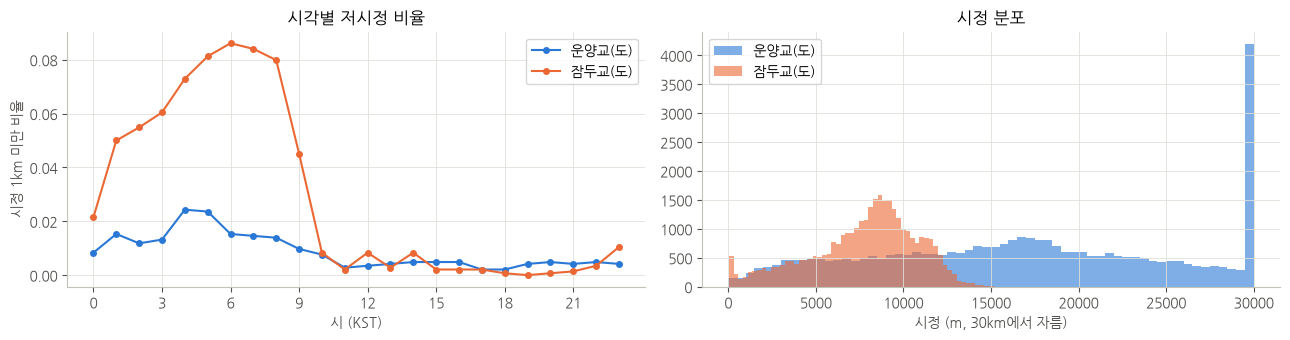

,count,mean,std,min,25%,50%,75%,max
관측 지점명,,,,,,,,
운양교(도),34559.0,17461.0,9505.0,0.0,10194.0,16833.0,23675.0,40008.0
잠두교(도),34559.0,7738.0,3042.0,47.0,5972.0,8256.0,9848.0,15955.0


In [9]:
fog["vis"] = fog["시정 (m)"].where(fog["시정 (m)"] >= 0)
fog["hour"], fog["month"] = fog["time"].dt.hour, fog["time"].dt.month
fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
for i, (stn, g) in enumerate(fog.groupby("stn")):
    name = g["관측 지점명"].iloc[0]
    axes[0].plot(range(24), g.groupby("hour")["vis"].apply(lambda s: (s < 1000).mean()), color=PALETTE[i],
                 marker="o", markersize=4, label=name)
    axes[1].hist(g["vis"].clip(upper=30000), bins=60, color=PALETTE[i], alpha=0.6, label=name)
axes[0].set_xticks(range(0, 24, 3))
axes[0].set_xlabel("시 (KST)")
axes[0].set_ylabel("시정 1km 미만 비율")
axes[0].set_title("시각별 저시정 비율")
axes[1].set_xlabel("시정 (m, 30km에서 자름)")
axes[1].set_title("시정 분포")
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.show()
fog.groupby("관측 지점명")["vis"].describe().round(0)

두 지점 모두 저시정(1km 미만)은 새벽~아침에 많고 산지의 잠두교가 운양교보다 3배 잦습니다(2.9% vs 0.9%). 잠두교는 시정 최댓값이 16km 정도로 낮아서 두 지점의 센서 측정 범위가 다른 것으로 보입니다. 2곳뿐이라 결빙 추정 변수로 쓰지 않았습니다. 안개·습도 효과는 AWS 습도와 하천 거리로 대신합니다.

## 저장

11-3의 고속도로 주변 교량 polygon과 고속도로 터널을 01-7에서 쓰도록 저장합니다.

In [10]:
for name, layer in {"bridge_poly": bridge_poly, "hw_tunnels": hw_tunnels}.items():
    path = config.INTERIM_DIR / f"{name}.gpkg"
    path.unlink(missing_ok=True)
    layer.to_file(path, driver="GPKG")
    print(f"{path.name}: {len(layer)}개")

bridge_poly.gpkg: 19449개
hw_tunnels.gpkg: 16개
